# Time series: from data structures to learned representations
**STAT3612 · Fall 2026 · Companion to the 34-slide tutorial**

Start at the top and choose **Restart Kernel and Run All Cells**. No data downloads, project files or GPU are needed. All observations and outcomes are synthetic; the numerical results are teaching examples, not medical findings or a model leaderboard.

**Before opening:** install `requirements.txt` from the repository root. Use the Python environment where you installed those packages.

Each section has a question, a few small code cells, and something to notice or try. You only need basic Python, arrays and DataFrames. Estimated study time: 60–90 minutes; the architecture details can be read later.

| Section | Question | Slides |
|---|---|---|
| [1. Data and tasks](#data) | What do the axes and outputs mean? | 3–5 |
| [2. Temporal patterns](#patterns) | Why does order matter? | 6–9 |
| [3. Preprocessing and features](#features) | How do gaps become model inputs? | 10–15 |
| [4. Development splits](#splits) | What should validation simulate? | 26–27 |
| [5. Tabular models](#models) | Can simple features predict an event? | 16, 25 |
| [6. Learned representations](#representations) | How do encoders and task heads work? | 17–21 |
| [7. ARIMA](#arima) | What do the parameters change? | 22–24 |
| [8. Evaluation](#evaluation) | How good are the probabilities? | 28–30 |
| [9. Project transfer](#project) | How do these ideas transfer to the files? | 31–34 |

We introduce the development split before fitting any models, even though the slides discuss validation later. **Core route:** sections 1–5, the opening of 6, and 8–9. Read the remaining sequence mechanics and forecasting examples at your own pace.

## Setup
We use NumPy for arrays, pandas for tables, Matplotlib for plots, scikit-learn for the small learned models, and statsmodels for ARIMA. Seeds make the simulations repeatable. Every plot is displayed inline; cells do not write data files.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import log_loss, roc_auc_score, average_precision_score
from sklearn.metrics import precision_score, recall_score, mean_absolute_error
from sklearn.calibration import calibration_curve
from statsmodels.tsa.arima.model import ARIMA

SEED = 3612
BLUE, TEAL, GOLD = "#075EA8", "#009D8C", "#D99E2B"
plt.rcParams.update({"figure.figsize": (9, 3), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

<a id="data"></a>
## 1. Add a time axis
**Question:** What changes when each patient has repeated readings?

Start with three patients and four hourly readings. An array's `.shape` tells us the size of each axis. Here the first axis identifies a patient and the second identifies an hour.

In [2]:
toy_hr = np.array([[60., 80., 100., 120.],
                   [120., 100., 80., 60.],
                   [80., 80., 80., 80.]])
print("One variable, several patients: N × L =", toy_hr.shape)
display(pd.DataFrame(toy_hr, index=["A", "B", "C"],
                     columns=["hour 0", "hour 1", "hour 2", "hour 3"]))

One variable, several patients: N × L = (3, 4)


,hour 0,hour 1,hour 2,hour 3
A,60.0,80.0,100.0,120.0
B,120.0,100.0,80.0,60.0
C,80.0,80.0,80.0,80.0


### Tabular features versus sequences
A summary table has shape $N\times D$: one row per example and $D$ features. A multivariate sequence has shape $N\times L\times F$: examples, observed time steps, measured channels. Adding a singleton channel axis changes the **shape**, not the observations.

In [3]:
toy_features = pd.DataFrame({"mean_hr": toy_hr.mean(axis=1),
                             "latest_hr": toy_hr[:, -1],
                             "change_hr": toy_hr[:, -1] - toy_hr[:, 0]},
                            index=["A", "B", "C"])
toy_sequence = toy_hr[:, :, None]  # add the channel axis
print("Summary table N × D:", toy_features.shape)
print("Univariate sequence N × L × F:", toy_sequence.shape)
print("One patient's L × F matrix:", toy_sequence[0].shape)
display(toy_features)

Summary table N × D: (3, 3)
Univariate sequence N × L × F: (3, 4, 1)
One patient's L × F matrix: (4, 1)


,mean_hr,latest_hr,change_hr
A,90.0,120.0,60.0
B,90.0,60.0,-60.0
C,80.0,80.0,0.0


### Our running dataset
We simulate **400 different patients**, each with 30 hourly readings of heart rate, systolic blood pressure and temperature. The first 24 hours are the input; the following 6 hours define a numerical forecast target and a toy binary event.

The event is “average heart rate over hours 24–29 exceeds 100.” This is an artificial outcome, **not a definition of sepsis**. We generate complete sequences first, then introduce missing observations into the input only. All examples assume the event is not already defined by an observed diagnosis at the cutoff.

In [4]:
rng = np.random.default_rng(SEED)
N, L, F, H = 400, 24, 3, 6
hours = np.arange(L + H)
level = rng.normal(85, 8, (N, 1))
slope = rng.normal(0.25, 0.55, (N, 1))
phase = rng.uniform(0, 2 * np.pi, (N, 1))
hr_complete = (level + slope * hours + 4 * np.sin(2 * np.pi * hours / 24 + phase)
               + rng.normal(0, 2, (N, L + H)))
bp_complete = 120 - 0.6 * (hr_complete - 85) + rng.normal(0, 3, hr_complete.shape)
temp_complete = 37 + 0.015 * (hr_complete - 85) + rng.normal(0, 0.1, hr_complete.shape)
complete = np.stack([hr_complete, bp_complete, temp_complete], axis=-1)

X = complete[:, :L].copy()                  # information available at the cutoff
future = complete[:, L:].copy()              # outcomes: never input features
y = (future[:, :, 0].mean(axis=1) > 100).astype(int)
X[rng.random(X.shape) < 0.08] = np.nan
X[0, 7:13, 0] = np.nan                      # one visible charting gap
channels = ["Heart rate", "Systolic BP", "Temperature"]
print("Input:", X.shape, "Forecast targets:", future.shape, "Binary targets:", y.shape)
assert X.shape == (N, L, F) and future.shape == (N, H, F)

Input: (400, 24, 3) Forecast targets: (400, 6, 3) Binary targets: (400,)


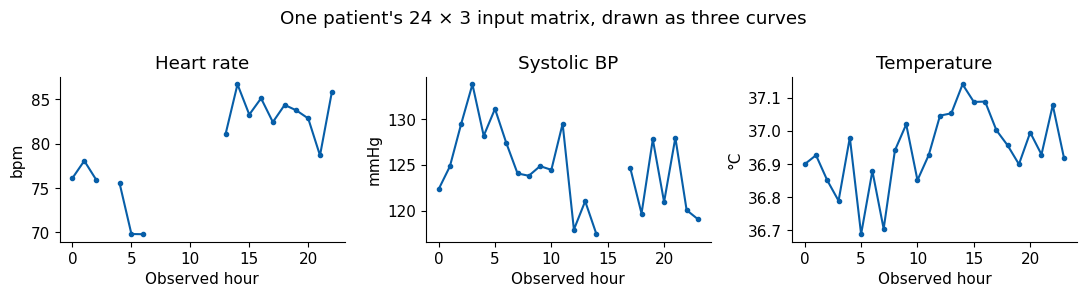

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for channel, ax in enumerate(axes):
    ax.plot(np.arange(L), X[0, :, channel], "o-", color=BLUE, markersize=3)
    ax.set(title=channels[channel], xlabel="Observed hour")
axes[0].set_ylabel("bpm")
axes[1].set_ylabel("mmHg")
axes[2].set_ylabel("°C")
fig.suptitle("One patient's 24 × 3 input matrix, drawn as three curves")
plt.tight_layout()
plt.show()

### Same input, different tasks
For all tasks below, the input is $N\times L\times F$. The target and head determine the output. This table describes output **shapes**; it does not pretend that we trained four models.

In [6]:
C = 3  # for example: three possible states at each observed hour
shape_table = pd.DataFrame([
    ["Forecasting", "Next 6 hours, all 3 channels", (N, H, F), "Real values"],
    ["Binary classification", "One event probability per patient", (N, 1), "Probability"],
    ["Sequence labeling", "3 state probabilities per observed hour", (N, L, C), "Probabilities"],
    ["Anomaly detection", "One unusualness score per observed hour", (N, L), "Scores"],
], columns=["Task", "Output meaning", "Output shape", "Output type"])
display(shape_table)

,Task,Output meaning,Output shape,Output type
0,Forecasting,"Next 6 hours, all 3 channels","(400, 6, 3)",Real values
1,Binary classification,One event probability per patient,"(400, 1)",Probability
2,Sequence labeling,3 state probabilities per observed hour,"(400, 24, 3)",Probabilities
3,Anomaly detection,One unusualness score per observed hour,"(400, 24)",Scores


**Notice:** binary labels are often stored as `(N,)`, even when a network outputs `(N, 1)`. Sequence labels can be integer IDs of shape `(N, L)`, while predicted class probabilities have shape `(N, L, C)`.

**Try:** if we forecast only heart rate for one hour, what are $H$ and $K$, the number of forecast channels? What is the output shape?

<details><summary>Check the shape exercise</summary>Here H = 1 and K = 1, so the forecast output is (N, 1, 1). A library may simplify this to (N, 1) or (N,), but the task still has one future time and one channel.</details>

<a id="patterns"></a>
## 2. Order is a property; trend is a pattern
A rising sequence and its reverse have the same mean and histogram. A cycle also depends on order, even when there is no sustained upward or downward trend.

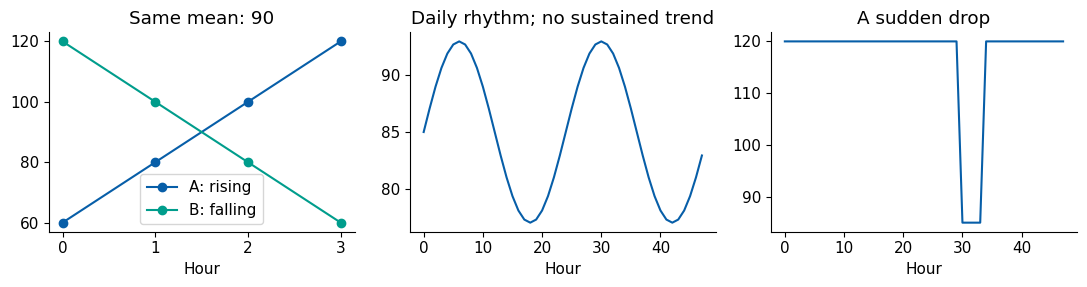

In [7]:
t = np.arange(48)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
axes[0].plot(toy_hr[0], "o-", label="A: rising", color=BLUE)
axes[0].plot(toy_hr[1], "o-", label="B: falling", color=TEAL)
axes[0].set(title="Same mean: 90", xlabel="Hour")
axes[0].legend()
axes[1].plot(t, 85 + 8 * np.sin(2 * np.pi * t / 24), color=BLUE)
axes[1].set(title="Daily rhythm; no sustained trend", xlabel="Hour")
shock = np.full(48, 120.)
shock[30:34] -= 35
axes[2].plot(t, shock, color=BLUE)
axes[2].set(title="A sudden drop", xlabel="Hour")
plt.tight_layout()
plt.show()

**Check your understanding:** shuffling time preserves the mean. Does it preserve the latest value, first-to-last change, or correlation between adjacent readings? Which of these could help a model?

<a id="features"></a>
## 3. From observations to usable features
### 3.1 Set the prediction cutoff first
The cutoff is the end of hour 23. The target uses hours 24–29. A measurement can only be a feature if it is available by the cutoff. A model cannot fix a feature that already contains future information.

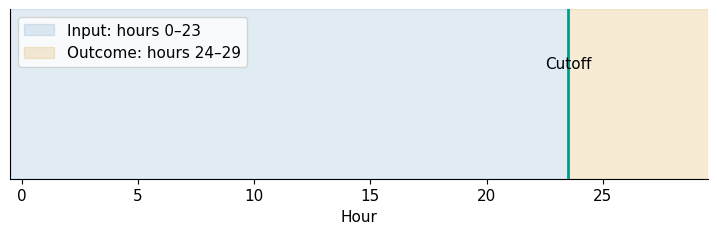

In [8]:
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.axvspan(-0.5, 23.5, color=BLUE, alpha=0.12, label="Input: hours 0–23")
ax.axvspan(23.5, 29.5, color=GOLD, alpha=0.2, label="Outcome: hours 24–29")
ax.axvline(23.5, color=TEAL, linewidth=2)
ax.text(23.5, 0.65, "Cutoff", ha="center")
ax.set(xlim=(-0.5, 29.5), ylim=(0, 1), yticks=[], xlabel="Hour")
ax.legend(loc="upper left")
plt.show()

### 3.2 A missing reading is not a zero
Compare three fills for the same gap. The mean below is computed **within this one fully observed input window**, not from other patients or future outcomes. Interpolation uses both sides of the gap, so it is suitable here only because the whole input window is available. An online alert must use only readings available at that alert time.

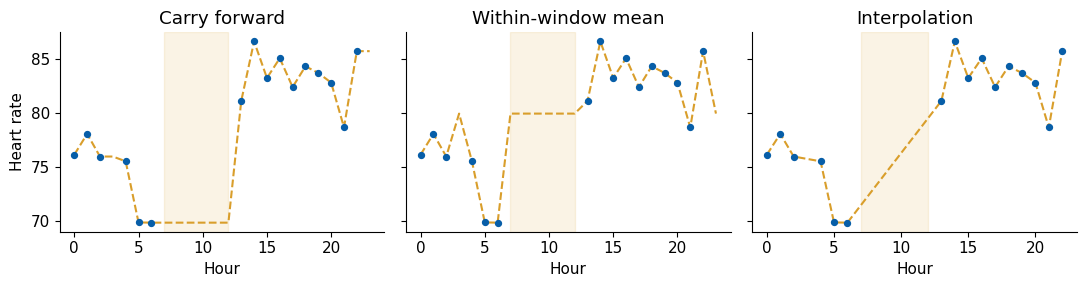

In [9]:
patient_hr = pd.Series(X[0, :, 0], index=np.arange(L))
fills = pd.DataFrame({
    "Carry forward": patient_hr.ffill(limit=6),
    "Within-window mean": patient_hr.fillna(patient_hr.mean()),
    "Interpolation": patient_hr.interpolate(limit_area="inside"),
})
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, name in zip(axes, fills):
    ax.plot(fills[name], "--", color=GOLD)
    ax.scatter(patient_hr.index, patient_hr, color=BLUE, s=18, zorder=3)
    ax.axvspan(7, 12, color=GOLD, alpha=0.12)
    ax.set(title=name, xlabel="Hour")
axes[0].set_ylabel("Heart rate")
plt.tight_layout()
plt.show()

**Notice:** the dashed line is a modeling choice, not a recovered measurement. Keep a missingness indicator or time since the last measurement. Forward filling cannot fill a missing first reading without some additional rule.

### 3.3 Irregular readings versus event counts
First bin several irregular measurement times into hours. Multiple readings in an hour are averaged; an empty hour remains unknown. In a complete click log, an empty day instead means zero clicks.

In [10]:
readings = pd.DataFrame({"hour": [0.2, 0.8, 2.3, 3.1], "hr": [80, 84, 90, 94]})
readings["bin"] = np.floor(readings["hour"]).astype(int)  # [0,1), [1,2), ...
hourly = readings.groupby("bin")["hr"].mean().reindex(range(4))
clicks = pd.DataFrame({"sample_id": ["A", "A", "B"], "day": [0, 0, 1],
                       "clicks": [2, 3, 7]})
daily = clicks.pivot_table(index="sample_id", columns="day", values="clicks",
                           aggfunc="sum", fill_value=0)
daily = daily.reindex(index=["A", "B", "C"], columns=range(4), fill_value=0)
display(hourly.to_frame("hourly_hr"), daily)
assert np.isnan(hourly.loc[1]) and hourly.loc[0] == 82
assert daily.loc["A", 0] == 5 and daily.loc["A", 1] == 0
assert daily.loc["C"].eq(0).all()  # C exists in our sample list, but has no events

,hourly_hr
bin,
0,82.0
1,NaN
2,90.0
3,94.0


day,0,1,2,3
sample_id,,,,
A,5,0,0,0
B,0,7,0,0
C,0,0,0,0


### 3.4 Summarize level, recency, change and missingness
This function sees only the input tensor. It produces one row per patient. pandas means skip missing readings; an entirely missing window remains NaN and will be handled by the fitted imputer later.

In [11]:
def make_features(sequence):
    hr = pd.DataFrame(sequence[:, :, 0])
    bp = pd.DataFrame(sequence[:, :, 1])
    temp = pd.DataFrame(sequence[:, :, 2])
    return pd.DataFrame({
        "mean_hr": hr.mean(axis=1),
        "latest_hr": hr.ffill(axis=1).iloc[:, -1],
        "last_6h_hr": hr.iloc[:, -6:].mean(axis=1),
        "change_hr": hr.iloc[:, -6:].mean(axis=1) - hr.iloc[:, -12:-6].mean(axis=1),
        "std_hr": hr.std(axis=1),
        "min_bp": bp.min(axis=1),
        "mean_temp": temp.mean(axis=1),
        "missing_hr_fraction": hr.isna().mean(axis=1),
    })

Z = make_features(X)
print("Sequence", X.shape, "→ feature table", Z.shape)
display(Z.head())
assert len(Z) == N and "future" not in Z.columns

Sequence (400, 24, 3) → feature table (400, 8)


,mean_hr,latest_hr,last_6h_hr,change_hr,std_hr,min_bp,mean_temp,missing_hr_fraction
0,79.952388,85.764645,83.071504,-0.648054,5.336333,117.430624,36.943796,0.333333
1,86.932632,82.829663,85.537693,-4.490223,3.709543,109.714022,37.021504,0.083333
2,83.408900,79.111841,81.443860,-5.512799,3.750217,115.818038,36.952727,0.166667
3,83.080819,84.931336,83.267298,1.496337,2.360582,115.819192,36.961340,0.083333
4,97.418511,102.728496,97.009647,1.077741,3.068953,103.328731,37.219492,0.000000


**Try:** add time since the last observed heart rate. Should “no observation in the entire window” have a special value or indicator? The latest observed value above need not be from hour 23.

The function takes no targets or future measurements. Cross-patient imputation and scaling are learned later, inside a pipeline.

<a id="splits"></a>
## 4. Define development and final-test partitions
**Question:** Are we predicting new patients, future admissions, or both?

Here every example is a different patient, and admissions are two days apart. We train on the first 60%, validate on the next 20%, and reserve the final 20%. The two-day spacing also ensures earlier outcomes are known before the next admission. This is **one demonstration split**, not a required project split.

Validation is development data: inspect it, change features, tune models, and revise your split. If validation statistics help fit preprocessing, those rows have joined fitting; their score is no longer an independent estimate. We use train-fitted pipelines here for a cleaner comparison. The final test stays outside model selection.

In [12]:
metadata = pd.DataFrame({"patient_id": np.arange(N),
                         "admitted": pd.date_range("2025-01-01", periods=N, freq="2D")})
metadata["label_available"] = metadata["admitted"] + pd.Timedelta(hours=L + H)
train_idx = np.arange(0, 240)
val_idx = np.arange(240, 320)
test_idx = np.arange(320, 400)
partitions = {"Train": train_idx, "Validation": val_idx, "Final test": test_idx}
display(pd.DataFrame([
    [name, len(idx), metadata.loc[idx, "admitted"].min(),
     metadata.loc[idx, "admitted"].max()] for name, idx in partitions.items()
], columns=["Partition", "Examples", "First admission", "Last admission"]))
assert set(train_idx).isdisjoint(val_idx) and set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)
assert metadata.loc[train_idx, "label_available"].max() < metadata.loc[val_idx, "admitted"].min()
assert metadata.loc[val_idx, "label_available"].max() < metadata.loc[test_idx, "admitted"].min()

,Partition,Examples,First admission,Last admission
0,Train,240,2025-01-01,2026-04-24
1,Validation,80,2026-04-26,2026-10-01
2,Final test,80,2026-10-03,2027-03-10


### Why “same patient twice” and “wrong unit” are one issue
The next tiny example has four rows for each patient. A random **row** split can put the same person on both sides. A grouped split protects a claim about **unseen people**. This toy exercise does not change our main split. For future predictions on known patients, time separation may be the appropriate requirement instead.

In [13]:
row_patient_ids = np.repeat(np.arange(8), 4)
row_train, row_val = train_test_split(np.arange(32), test_size=0.25, random_state=SEED)
grouper = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
group_train, group_val = next(grouper.split(np.zeros((32, 1)), groups=row_patient_ids))

def shared_people(left, right):
    return set(row_patient_ids[left].tolist()) & set(row_patient_ids[right].tolist())

print("People shared by random row split:", sorted(shared_people(row_train, row_val)))
print("People shared by grouped split:", sorted(shared_people(group_train, group_val)))
assert shared_people(row_train, row_val)
assert not shared_people(group_train, group_val)

People shared by random row split: [0, 1, 2, 3, 6, 7]
People shared by grouped split: []


**Three boundaries:**
1. **Time:** exclude information first available after the prediction cutoff.
2. **Evaluation unit:** group related rows when the goal is unseen-person performance.
3. **Final test:** keep its statistics, labels and feedback out of development.

We have computed per-example features for all rows, but have not learned any cross-example transformation from validation or test. The next cells learn imputation and scaling from training rows only.

<a id="models"></a>
## 5. Fit simple tabular models
### 5.1 Start with a constant probability
Our baseline gives everyone the event rate in the training partition. Log loss measures probability quality: smaller is better. We inspect **validation** performance while developing models.

In [14]:
training_event_rate = y[train_idx].mean()
baseline_val = np.full(len(val_idx), training_event_rate)
validation_probabilities = {"Constant probability": baseline_val}
print(f"Training event rate: {training_event_rate:.3f}")
print(f"Validation log loss: {log_loss(y[val_idx], baseline_val):.3f}")

Training event rate: 0.283
Validation log loss: 0.658


### 5.2 Give the model temporal information
A pipeline keeps imputation, scaling and prediction together. `.fit()` learns the entire pipeline; `.predict_proba()` applies those learned steps and returns probabilities.

We compare a mean-only logistic model, logistic regression with all features, and a small random forest. This is a learning exercise, not a search for the best architecture.

In [15]:
linear = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                       StandardScaler(), LogisticRegression(C=1, max_iter=500))
trees = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                      RandomForestClassifier(n_estimators=100, max_depth=4,
                                             min_samples_leaf=8, random_state=SEED,
                                             n_jobs=1))
candidates = {
    "Constant probability": (DummyClassifier(strategy="prior"), Z),
    "Mean only": (clone(linear), Z[["mean_hr"]]),
    "Temporal features + logistic": (linear, Z),
    "Temporal features + forest": (trees, Z),
}
for name, (model, inputs) in candidates.items():
    model.fit(inputs.iloc[train_idx], y[train_idx])
    validation_probabilities[name] = model.predict_proba(inputs.iloc[val_idx])[:, 1]

display(pd.Series({name: log_loss(y[val_idx], prob)
                   for name, prob in validation_probabilities.items()},
                  name="Validation log loss").sort_values().to_frame())

,Validation log loss
Temporal features + logistic,0.118984
Temporal features + forest,0.122582
Mean only,0.238622
Constant probability,0.657940


**Notice:** the synthetic label was created from future heart rate, so recent level and change have a plausible connection to it. Real data may behave differently. A random forest is not guaranteed to beat a linear model.

**Try:** compare mean + latest value against mean + change. Keep the validation rows and metric fixed while comparing. Do not choose features by looking at the final test.

<a id="representations"></a>
## 6. Learn a representation, then attach a task head
### 6.1 A tiny trained encoder
An encoder maps inputs to useful hidden features. A task head maps those features to the required output. We can see this idea with a small dense neural network using scikit-learn; no GPU is needed.

For this first model, flatten each $24\times3$ window into 72 ordered entries. The hidden layer learns 8 features; the final layer learns a binary probability. **This is a dense network, not an RNN:** it uses fixed positions and does not share a recurrent update across time. We add RNN/GRU/attention mechanics below.

In [16]:
flat_X = pd.DataFrame(X.reshape(N, L * F))
sequence_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(8,), activation="tanh", solver="lbfgs",
                  alpha=10, max_iter=1000, random_state=SEED),
)
sequence_model.fit(flat_X.iloc[train_idx], y[train_idx])
candidates["Dense sequence encoder"] = (sequence_model, flat_X)
validation_probabilities["Dense sequence encoder"] = sequence_model.predict_proba(
    flat_X.iloc[val_idx])[:, 1]
print("Input window → flattened input → learned representation → binary probability")
print((L, F), "→", L * F, "→", 8, "→", 1)

Input window → flattened input → learned representation → binary probability
(24, 3) → 72 → 8 → 1


Retrieve the learned hidden layer directly. The network has learned both its encoder weights and classification head. We reconstruct the prediction to check that this interpretation matches the library model.

Learned training representations: (240, 8)


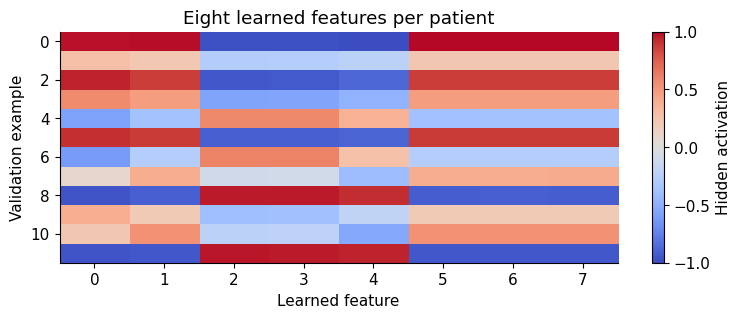

In [17]:
preprocessor = sequence_model[:-1]
network = sequence_model.named_steps["mlpclassifier"]

def encode(rows):
    scaled = preprocessor.transform(flat_X.iloc[rows])
    return np.tanh(scaled @ network.coefs_[0] + network.intercepts_[0])

representation_train = encode(train_idx)
representation_val = encode(val_idx)
logits = representation_val @ network.coefs_[1] + network.intercepts_[1]
manual_probability = 1 / (1 + np.exp(-logits[:, 0]))
np.testing.assert_allclose(manual_probability,
                           validation_probabilities["Dense sequence encoder"])
print("Learned training representations:", representation_train.shape)
plt.imshow(representation_val[:12], aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
plt.xlabel("Learned feature")
plt.ylabel("Validation example")
plt.title("Eight learned features per patient")
plt.colorbar(label="Hidden activation")
plt.show()

### 6.2 The representation can support another task
Fit a **forecast head** on the training representations: predict heart rate for the next six hours. The head has six numeric outputs instead of one probability. The encoder is frozen here, so this demonstrates reuse; an encoder trained jointly for forecasting might learn different features.

Classification is only one use of a representation. For sequence labeling, keep a representation at every observed step; for anomaly detection, one possibility is to score unusually large forecast or reconstruction errors.

Forecast output: (80, 6) = validation examples × 6 future hours
Validation forecast MAE: 4.81 bpm


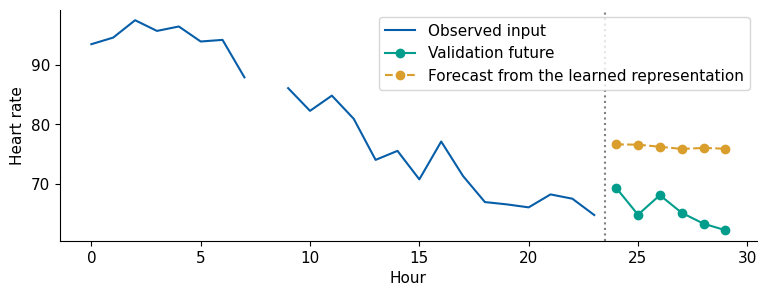

In [18]:
forecast_head = Ridge(alpha=10)
forecast_head.fit(representation_train, future[train_idx, :, 0])
validation_forecast = forecast_head.predict(representation_val)
print("Forecast output:", validation_forecast.shape, "= validation examples × 6 future hours")
print(f"Validation forecast MAE: {mean_absolute_error(future[val_idx, :, 0], validation_forecast):.2f} bpm")
example = 0
plt.plot(np.arange(L), X[val_idx[example], :, 0], color=BLUE, label="Observed input")
plt.plot(np.arange(L, L + H), future[val_idx[example], :, 0], "o-", color=TEAL,
         label="Validation future")
plt.plot(np.arange(L, L + H), validation_forecast[example], "o--", color=GOLD,
         label="Forecast from the learned representation")
plt.axvline(L - 0.5, color="gray", linestyle=":")
plt.xlabel("Hour")
plt.ylabel("Heart rate")
plt.legend()
plt.show()

**Notice the forecast above:** reusing a representation does not guarantee an accurate forecast. A classifier can learn to separate “above the threshold” from “below” without preserving the exact future level. A forecast-trained encoder or a simple persistence baseline is a useful comparison.

### 6.3 RNN mechanics: one shared update at each step (optional detail)
An RNN uses $h_t=\tanh(x_tW_x+h_{t-1}W_h+b)$. The same weights are reused at every time step. We use row vectors here, so the matrix orientation differs from the slide's column-vector notation.

**The next RNN and GRU weights are fixed random numbers, not trained models.** They illustrate memory and shapes; their hidden states are not meaningful clinical features. Training would adjust these weights using a task loss.

One state per time step: (24, 4)
A window representation from the final step: (4,)


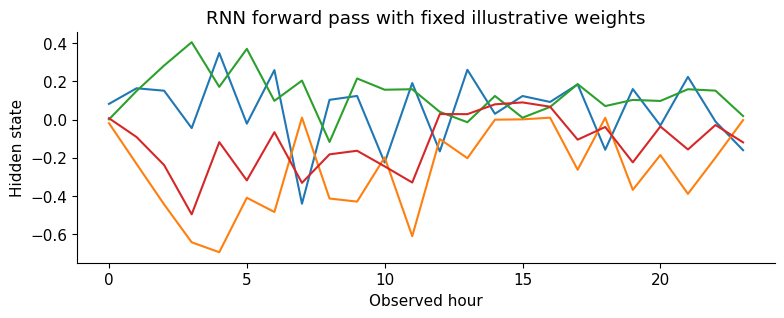

In [19]:
example_sequence = preprocessor.transform(flat_X.iloc[[train_idx[0]]]).reshape(L, F)
weights_rng = np.random.default_rng(SEED)
hidden_size = 4
W_x = weights_rng.normal(0, 0.2, (F, hidden_size))
W_h = weights_rng.normal(0, 0.2, (hidden_size, hidden_size))
h = np.zeros(hidden_size)
rnn_states = []
for x_t in example_sequence:
    h = np.tanh(x_t @ W_x + h @ W_h)
    rnn_states.append(h.copy())
rnn_states = np.array(rnn_states)
print("One state per time step:", rnn_states.shape)
print("A window representation from the final step:", rnn_states[-1].shape)
plt.plot(rnn_states)
plt.xlabel("Observed hour")
plt.ylabel("Hidden state")
plt.title("RNN forward pass with fixed illustrative weights")
plt.show()

### 6.4 GRU mechanics: gates decide what to retain (optional detail)
The **reset gate** controls how much past state enters a candidate. The **update gate** mixes the old state with that candidate. In this convention, $z$ near 1 retains more of the old state:
$$h_t=z_t\odot h_{t-1}+(1-z_t)\odot\widetilde h_t.$$
The gate values are computed from input and state, not selected by hand. This is a simplified GRU with no biases. An LSTM adds a separate cell-memory state; it follows the same broad idea of gated memory.

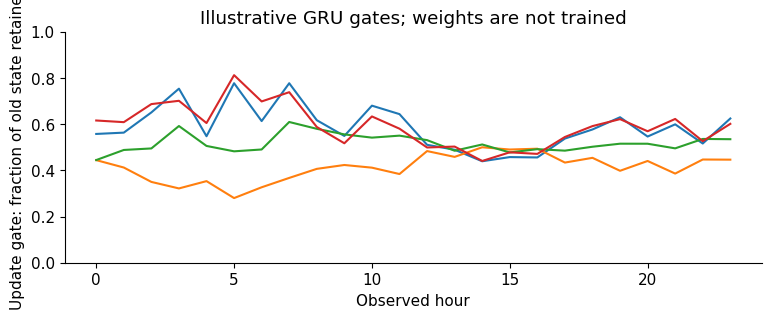

In [20]:
def sigmoid(a):
    return 1 / (1 + np.exp(-a))

W_reset = weights_rng.normal(0, 0.2, (F + hidden_size, hidden_size))
W_update = weights_rng.normal(0, 0.2, (F + hidden_size, hidden_size))
W_candidate = weights_rng.normal(0, 0.2, (F + hidden_size, hidden_size))
h = np.zeros(hidden_size)
gru_states, update_gates = [], []
for x_t in example_sequence:
    joined = np.concatenate([x_t, h])
    reset = sigmoid(joined @ W_reset)
    update = sigmoid(joined @ W_update)
    candidate = np.tanh(np.concatenate([x_t, reset * h]) @ W_candidate)
    h = update * h + (1 - update) * candidate
    gru_states.append(h.copy())
    update_gates.append(update)
plt.plot(np.array(update_gates))
plt.ylim(0, 1)
plt.xlabel("Observed hour")
plt.ylabel("Update gate: fraction of old state retained")
plt.title("Illustrative GRU gates; weights are not trained")
plt.show()

### 6.5 Attention: compare time steps directly (optional detail)
Attention combines value vectors using weights derived from query/key similarity:
$$A=\operatorname{softmax}(QK^\top/\sqrt{d_k}),\qquad H=AV.$$

Here we use the first eight hours and set $Q=K=V$ to a simple input embedding. A small sine/cosine time encoding tells the computation about position. A full Transformer learns projections and adds multiple heads, feed-forward layers, residual connections and normalization. This example isolates attention; it is not a trained Transformer or an explanation of a model's decisions.

In [21]:
time = np.arange(8)
time_encoding = np.column_stack([np.sin(time / 4), np.cos(time / 4), time / 8])
tokens = example_sequence[:8] + 0.2 * time_encoding
Q = K = V = tokens
scores = Q @ K.T / np.sqrt(tokens.shape[1])

def softmax_rows(values):
    exp_values = np.exp(values - values.max(axis=1, keepdims=True))
    return exp_values / exp_values.sum(axis=1, keepdims=True)

full_attention = softmax_rows(scores)
future_positions = np.triu(np.ones((8, 8), dtype=bool), k=1)
causal_attention = softmax_rows(np.where(future_positions, -np.inf, scores))
# Imagine a shorter, six-hour example padded to eight positions.
padding_positions = np.arange(8) >= 6
padding_attention = softmax_rows(np.where(padding_positions[None, :], -np.inf, scores))
attended_states = full_attention @ V
assert np.allclose(full_attention.sum(axis=1), 1)
assert np.all(causal_attention[future_positions] == 0)
assert np.all(padding_attention[:, padding_positions] == 0)
print("Time-step representations:", attended_states.shape)

Time-step representations: (8, 3)


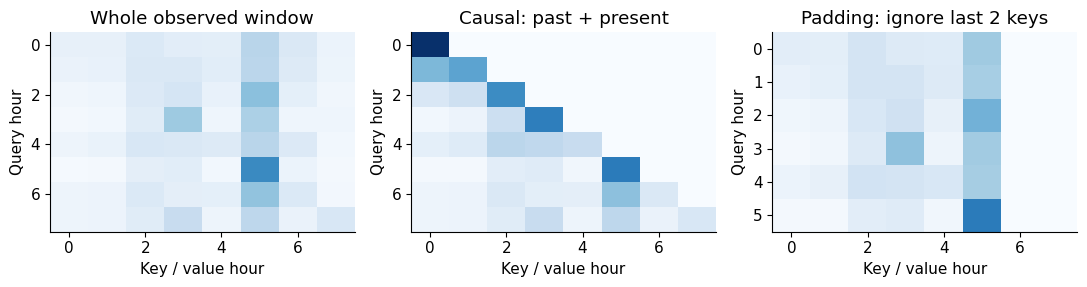

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, weights, title in zip(axes,
        [full_attention, causal_attention, padding_attention[:6]],
        ["Whole observed window", "Causal: past + present", "Padding: ignore last 2 keys"]):
    image = ax.imshow(weights, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set(title=title, xlabel="Key / value hour", ylabel="Query hour")
plt.tight_layout()
plt.show()

**Read a row:** it shows which input hours contribute to one query hour. In the causal plot, everything above the diagonal is zero.

- **Whole-window prediction:** all hours 0–23 are already observed; full attention within them is allowed.
- **Online prediction:** each step may see only its past and present.
- **Autoregressive forecast training:** pair each input with the next-step target and use a causal mask.
- **Padding:** mask nonexistent keys and exclude padded query outputs from pooling or the loss. The third plot shows only the six real queries.

**Try:** remove the time encoding. What could a permutation-invariant pooling layer lose if the encoder only compared content? A causal mask cannot remove future information already inserted into a feature.

In [23]:
# A teacher-forcing pair: the target is one step ahead of the input.
short_sequence = np.array([80., 84., 90., 95.])
display(pd.DataFrame({"input at t": short_sequence[:-1],
                      "target at t+1": short_sequence[1:]}))

,input at t,target at t+1
0,80.0,84.0
1,84.0,90.0
2,90.0,95.0


<a id="arima"></a>
## 7. Forecasting with ARIMA
**Question:** How do past values, differences and past surprises help predict a numeric series?

For ARIMA $(p,d,q)$:
- $d$ tells us how many times to difference the levels.
- $p$ counts recent values of the **differenced series** used in prediction.
- $q$ counts past innovations (estimated one-step prediction errors).

MA means a weighted combination of surprises, not a rolling mean of the data. The orders specify how many lags; fitting learns their weights.

This section uses a **separate, longer synthetic monitoring series**. A 24-hour patient window is too short to make a useful general ARIMA demonstration. These forecasts do not enter our classifier comparison.

### 7.1 Difference first; restore the level afterwards
In this simulated series, the increments are stable while the level drifts. One difference is appropriate. Two differences are unnecessary here; a visible upward trend does not mean every series needs differencing.

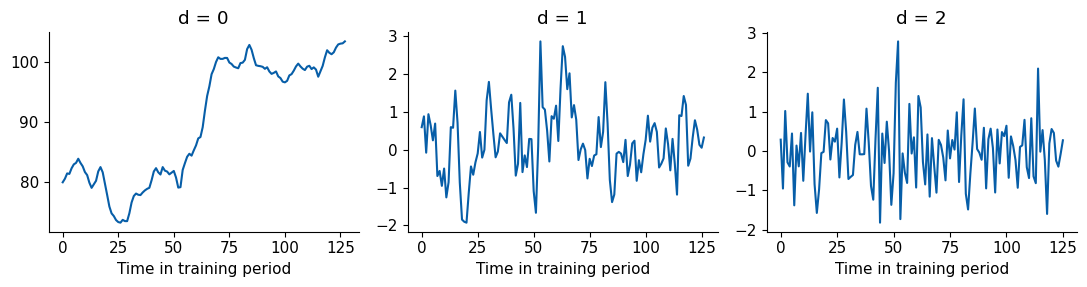

Levels [80, 84, 90] → changes [4 6]
If the next change is 5, the next level is 95


In [24]:
forecast_rng = np.random.default_rng(SEED + 1)
innovations = forecast_rng.normal(0, 0.8, 161)
changes = np.zeros(160)
for t in range(1, 160):
    changes[t] = 0.3 + 0.4 * changes[t - 1] + innovations[t] + 0.3 * innovations[t - 1]
monitoring = 80 + np.cumsum(changes)
forecast_train = monitoring[:128]
forecast_val = monitoring[128:]
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for d, ax in enumerate(axes):
    values = np.diff(forecast_train, n=d)
    ax.plot(values, color=BLUE)
    ax.set(title=f"d = {d}", xlabel="Time in training period")
plt.tight_layout()
plt.show()
print("Levels [80, 84, 90] → changes", np.diff([80, 84, 90]))
print("If the next change is 5, the next level is", 90 + 5)

### 7.2 Fit and draw a forecast
We use `(1, 1, 1)` as an illustration, not a universal starting rule. With one difference, `trend="t"` specifies a linear trend in the original levels (a drift after differencing); a constant level term would be removed by differencing.

Only the training prefix is passed to `.fit()`. The held-out suffix is validation for this forecasting example.

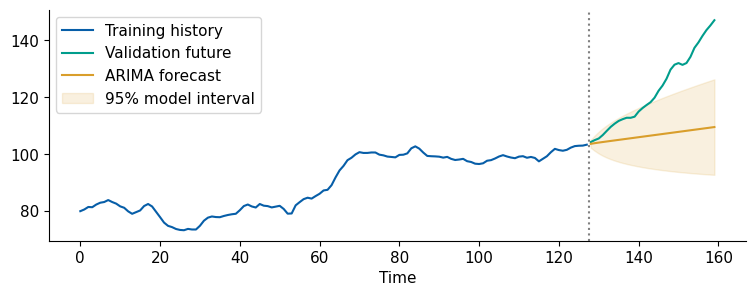

Validation MAE: 15.79


In [25]:
arima = ARIMA(forecast_train, order=(1, 1, 1), trend="t").fit()
forecast_result = arima.get_forecast(steps=len(forecast_val))
forecast_mean = np.asarray(forecast_result.predicted_mean)
forecast_interval = np.asarray(forecast_result.conf_int())
future_time = np.arange(len(forecast_train), len(monitoring))
plt.plot(np.arange(len(forecast_train)), forecast_train, color=BLUE, label="Training history")
plt.plot(future_time, forecast_val, color=TEAL, label="Validation future")
plt.plot(future_time, forecast_mean, color=GOLD, label="ARIMA forecast")
plt.fill_between(future_time, forecast_interval[:, 0], forecast_interval[:, 1],
                 color=GOLD, alpha=0.15, label="95% model interval")
plt.axvline(len(forecast_train) - 0.5, color="gray", linestyle=":")
plt.xlabel("Time")
plt.legend()
plt.show()
print(f"Validation MAE: {mean_absolute_error(forecast_val, forecast_mean):.2f}")
assert arima.mle_retvals["converged"]

**Notice:** the future is a range of possibilities. In the saved run, much of the rising validation path lies outside the interval: fitting an ARIMA model does not guarantee a good forecast. These intervals depend on model assumptions and are not a guarantee of empirical coverage. We omit ACF/PACF order-identification rules here.

### 7.3 Seasonal and external-predictor variants
| Family | Extension | Example |
|---|---|---|
| AR / MA / ARMA | Set $d=0$; use value/error lags | A stable series |
| ARIMA | Difference before modeling | A drifting level |
| SARIMA | Add $(P,D,Q)_s$ | Seasonal lags and seasonal differences |
| ARIMAX / SARIMAX | Include external predictors | A calendar or known schedule |

$P,D,Q$ have the same roles as $p,d,q$, but at seasonal lags. $s=24$ for a daily cycle in hourly data; $s=7$ for a weekly cycle in daily data. $D=1$ uses $y_t-y_{t-s}$. The seasonal period is not the forecast horizon.

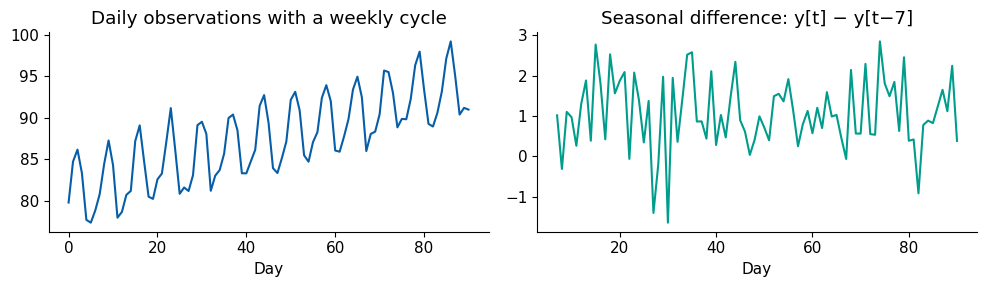

In [26]:
days = np.arange(112)
weekly_rng = np.random.default_rng(SEED + 2)
weekend = (days % 7 >= 5).astype(float)
calendar = pd.DataFrame({"time": days / 100, "weekend": weekend})
daily_series = (80 + 0.15 * days + 6 * np.sin(2 * np.pi * days / 7)
                + 3 * weekend + weekly_rng.normal(0, 0.7, len(days)))
weekly_cutoff = 91
seasonal_difference = daily_series[7:weekly_cutoff] - daily_series[:weekly_cutoff - 7]
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(days[:weekly_cutoff], daily_series[:weekly_cutoff], color=BLUE)
axes[0].set(title="Daily observations with a weekly cycle", xlabel="Day")
axes[1].plot(days[7:weekly_cutoff], seasonal_difference, color=TEAL)
axes[1].set(title="Seasonal difference: y[t] − y[t−7]", xlabel="Day")
plt.tight_layout()
plt.show()

Fit one seasonal model with external calendar predictors. Both future calendar columns are known in advance. Future realized measurements would not be valid external inputs. In statsmodels, the `ARIMA` class can also express seasonal models and regression with ARIMA errors.

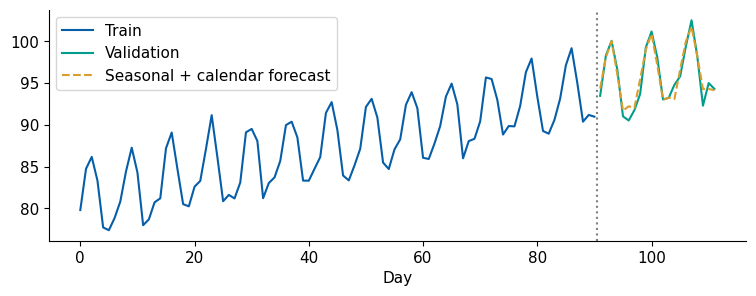

In [27]:
seasonal_model = ARIMA(
    daily_series[:weekly_cutoff],
    exog=calendar.iloc[:weekly_cutoff],
    order=(1, 0, 0), seasonal_order=(1, 0, 0, 7),
).fit(method_kwargs={"maxiter": 200})
seasonal_prediction = seasonal_model.forecast(
    steps=len(days) - weekly_cutoff, exog=calendar.iloc[weekly_cutoff:])
plt.plot(days[:weekly_cutoff], daily_series[:weekly_cutoff], color=BLUE, label="Train")
plt.plot(days[weekly_cutoff:], daily_series[weekly_cutoff:], color=TEAL, label="Validation")
plt.plot(days[weekly_cutoff:], np.asarray(seasonal_prediction), "--", color=GOLD,
         label="Seasonal + calendar forecast")
plt.axvline(weekly_cutoff - 0.5, color="gray", linestyle=":")
plt.xlabel("Day")
plt.legend()
plt.show()
assert seasonal_model.mle_retvals["converged"]

**Try:** compare with a simple seasonal-naive forecast (repeat the latest week) on the same validation horizon. Does the extra complexity help? A few well-motivated candidates are enough for this tutorial.

<a id="evaluation"></a>
## 8. Evaluate probabilities, then use the final test
### 8.1 Log loss rewards appropriate confidence
For one observation the loss is $-[y\log p+(1-y)\log(1-p)]$. Two probabilities can produce the same class decision but different losses. A confident wrong prediction is costly.

In [28]:
example_y = np.array([1, 1, 0])
example_p = np.array([0.6, 0.9, 0.9])
individual_loss = -(example_y * np.log(example_p) + (1 - example_y) * np.log(1 - example_p))
display(pd.DataFrame({"True class": example_y, "P(event)": example_p,
                      "Decision at 0.5": (example_p >= 0.5).astype(int),
                      "Log loss": individual_loss}).round(3))
np.testing.assert_allclose(individual_loss, [-np.log(0.6), -np.log(0.9), -np.log(0.1)])

,True class,P(event),Decision at 0.5,Log loss
0,1,0.6,1,0.511
1,1,0.9,1,0.105
2,0,0.9,1,2.303


### 8.2 Compare candidates on validation
Log loss evaluates probabilities; ROC-AUC evaluates ranking. Average precision (AP) summarizes the precision–recall curve and is useful when events are rare. **AP is not exactly the trapezoidal area under that curve.** None of these alone describes threshold decisions or performance in every subgroup.

All classification candidates below use the same examples, input window and target. Their input representations differ. These are results from one synthetic development split, not evidence of a general model ranking.

In [29]:
validation_results = pd.DataFrame([
    {"Model": name, "Log loss": log_loss(y[val_idx], prob),
     "ROC-AUC": roc_auc_score(y[val_idx], prob),
     "Average precision": average_precision_score(y[val_idx], prob)}
    for name, prob in validation_probabilities.items()
]).set_index("Model").sort_values("Log loss")
display(validation_results.round(3))
selected_name = validation_results.index[0]  # selection uses validation log loss only
selected_val_probability = validation_probabilities[selected_name]
print("Selected using validation:", selected_name)

,Log loss,ROC-AUC,Average precision
Model,,,
Temporal features + logistic,0.119,0.994,0.990
Temporal features + forest,0.123,0.995,0.991
Dense sequence encoder,0.130,0.996,0.992
Mean only,0.239,0.967,0.947
Constant probability,0.658,0.500,0.350


Selected using validation: Temporal features + logistic


### 8.3 Calibration and thresholds answer different questions
Calibration asks whether predicted risks match observed frequencies. Thresholds turn probabilities into decisions; lower thresholds usually trade more false positives for fewer missed positives. We inspect both on validation.

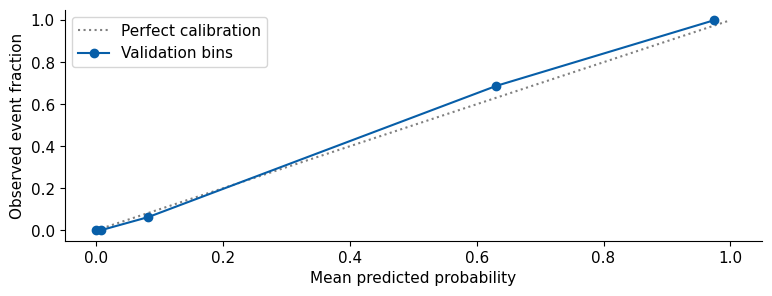

,Threshold,Precision,Recall
0,0.3,0.871,0.964
1,0.5,0.963,0.929
2,0.7,1.000,0.893


In [30]:
observed_rate, predicted_risk = calibration_curve(
    y[val_idx], selected_val_probability, n_bins=5, strategy="quantile")
plt.plot([0, 1], [0, 1], ":", color="gray", label="Perfect calibration")
plt.plot(predicted_risk, observed_rate, "o-", color=BLUE, label="Validation bins")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed event fraction")
plt.legend()
plt.show()
display(pd.DataFrame([
    {"Threshold": threshold,
     "Precision": precision_score(y[val_idx], selected_val_probability >= threshold, zero_division=0),
     "Recall": recall_score(y[val_idx], selected_val_probability >= threshold, zero_division=0)}
    for threshold in [0.3, 0.5, 0.7]
]).round(3))

**Notice:** with only 80 validation examples, calibration bins are noisy. Fitting a calibrator would use development data or cross-fitting, not final-test labels. Repeated validation exploration can also make its scores optimistic.

A single score can hide a weak subgroup. Here we inspect examples with different amounts of missing heart-rate data.

In [31]:
slice_boundary = Z.iloc[train_idx]["missing_hr_fraction"].median()
more_missing = Z.iloc[val_idx]["missing_hr_fraction"].to_numpy() > slice_boundary
slice_results = []
for name, mask in [("Less missing", ~more_missing), ("More missing", more_missing)]:
    if mask.any():
        slice_results.append({"Slice": name, "Examples": int(mask.sum()),
            "Log loss": log_loss(y[val_idx][mask], selected_val_probability[mask], labels=[0, 1])})
display(pd.DataFrame(slice_results).round(3))

,Slice,Examples,Log loss
0,Less missing,52,0.094
1,More missing,28,0.166


### 8.4 Freeze the choice, refit, and evaluate once
We now refit the selected pipeline on **train + validation**, then apply it to the final test. The imputer, scaler and model are all refitted using development data. No test statistic is used for fitting or model selection.

The final-test cell is a reporting endpoint. In a real study, using its score to redesign the model would turn that test into more development feedback; you would need a fresh independent test. Restarting this deterministic teaching notebook reproduces the same exercise.

In [32]:
development_idx = np.concatenate([train_idx, val_idx])
selected_template, selected_inputs = candidates[selected_name]
final_model = clone(selected_template)
final_model.fit(selected_inputs.iloc[development_idx], y[development_idx])
test_probability = final_model.predict_proba(selected_inputs.iloc[test_idx])[:, 1]
assert np.isfinite(test_probability).all()
assert np.all((test_probability >= 0) & (test_probability <= 1))
display(pd.Series({
    "Final-test log loss": log_loss(y[test_idx], test_probability),
    "Final-test ROC-AUC": roc_auc_score(y[test_idx], test_probability),
    "Final-test average precision": average_precision_score(y[test_idx], test_probability),
}).round(3).to_frame(selected_name))

,Temporal features + logistic
Final-test log loss,0.168
Final-test ROC-AUC,0.984
Final-test average precision,0.978


<a id="project"></a>
## 9. Transfer the ideas to the group project
The project predicts a two-week learning-platform pause:
- **One example:** one student in one module presentation.
- **Input:** days 0–28 inclusive (29 days), plus eligible information available by the cutoff.
- **Outcome:** days 29–42 inclusive (14 days). Zero recorded clicks means $y=1$.
- **Output:** a probability of $y=1$ for each test example.

The clinical-style simulation above provides a workflow, not a project solution. Use Moodle and Kaggle for the authoritative instructions, fields and submission format. No course data, staff benchmarks or hidden outcomes are included here.

### 9.1 Formats change the reader, not the DataFrame
| File | Reader | Role |
|---|---|---|
| `train.csv` | `pd.read_csv` | Labeled examples |
| `test.csv` | `pd.read_csv` | Unlabeled examples |
| `sample_submission.csv` | `pd.read_csv` | Submission format |
| `vle_events.parquet` | `pd.read_parquet` | Activity histories |
| `past_assessments.parquet` | `pd.read_parquet` | Eligible assessment histories |

CSV is portable text. Parquet is typed, compressed and can read selected columns; install `pyarrow` when working with the actual project Parquet files. JSON is convenient for nested records; JSONL has one record per line. Pickle is a local Python cache: only load trusted files, and expect version limitations.

The following executable example reads tiny **in-memory toy data**, so Run All works without project files.

In [33]:
from io import StringIO

toy_csv = "sample_id,day,clicks\nA,0,2\nA,0,3\nB,1,7\n"
loaded_csv = pd.read_csv(StringIO(toy_csv), dtype={"sample_id": "string"})
toy_jsonl = loaded_csv.to_json(orient="records", lines=True)
loaded_jsonl = pd.read_json(StringIO(toy_jsonl), lines=True, dtype={"sample_id": "string"})
display(loaded_csv)
print("CSV shape:", loaded_csv.shape, "JSONL shape:", loaded_jsonl.shape)
pd.testing.assert_frame_equal(loaded_csv, loaded_jsonl)

,sample_id,day,clicks
0,A,0,2
1,A,0,3
2,B,1,7


CSV shape: (3, 3) JSONL shape: (3, 3)


When you have the actual project files, use a separate working cell or notebook. These commands are shown as a reference and are **not required by Run All**:

```python
from pathlib import Path
project_dir = Path("/path/to/project/files")
train = pd.read_csv(project_dir / "train.csv", dtype={"sample_id": "string"})
test = pd.read_csv(project_dir / "test.csv", dtype={"sample_id": "string"})
vle = pd.read_parquet(project_dir / "vle_events.parquet",
                      columns=["sample_id", "day", "clicks"])
assessments = pd.read_parquet(project_dir / "past_assessments.parquet")
submission = pd.read_csv(project_dir / "sample_submission.csv")
```

Check `.head()`, `.shape` and `.dtypes` first. Both history tables contain train and test records: link by `sample_id`. Repeated day/type records may represent different sites, so aggregate them rather than treating every repeat as an error. `student_group` is a grouping key for repeated people, not a predictor.

### 9.2 Your turn: propose an approach
1. **Representation:** sketch the shape of a daily sequence and of a summary-feature table. How would you encode activity types?
2. **Baseline:** what probability would you predict before using any histories?
3. **Validation:** which deployment question does your split answer? How would you handle repeated students and later presentations?
4. **Improvement:** choose one change, compare validation log loss, and explain why it might help.
5. **Cutoff:** what happens if an assessment result or activity becomes available after day 28?

There is no required validation split or hidden “best model” in this notebook. Record your decisions and keep the final test outside development.

## Further reading
- [scikit-learn: pipelines and preprocessing pitfalls](https://scikit-learn.org/stable/common_pitfalls.html)
- [scikit-learn: MLPClassifier and learned weights](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)
- [Forecasting: Principles and Practice — ARIMA](https://otexts.com/fpp3/arima.html)
- [statsmodels: ARIMA, seasonal orders and external regressors](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html)
- [pandas: IO tools](https://pandas.pydata.org/docs/user_guide/io.html)

**Return to the central question:** what information is available at prediction time, how will you represent it, and what output does the task require?